In [1]:
import pandas as pd

df = pd.read_csv("output/tf_idf_matrix.csv")
df_labels = pd.read_csv("ML/tf_idf_matrix_clases.csv")

df.head()

,Unnamed: 0,abajo,abecedario,abierto,abono,abre,abren,abrimos,abrir,abrían,...,órdenes,última,último,últimos,única,único,únidos,útil,útiles,útilices
0,T1 Betzavel Laso Roman/04-03-2026,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,T1 Betzavel Laso Roman/13-02-2026,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,T1 Betzavel Laso Roman/16-02-2026,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,T1 Betzavel Laso Roman/19-01-2026,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,T1 Betzavel Laso Roman/22-01-2026,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [2]:
df_labels.head()

,Chat,Clase
0,T1 Betzavel Laso Roman/04-03-2026,Confirmación_Estado
1,T1 Betzavel Laso Roman/13-02-2026,Facturación_Documentos
2,T1 Betzavel Laso Roman/16-02-2026,Facturación_Documentos
3,T1 Betzavel Laso Roman/19-01-2026,Facturación_Documentos
4,T1 Betzavel Laso Roman/22-01-2026,Interacción/Relacional


## Preparación de datos
Unimos la matriz TF-IDF con las etiquetas por id de chat (los chats sin etiqueta se descartan) y agrupamos las clases con pocos ejemplos en `Otras`.

In [3]:
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

RANDOM_STATE = 42
MIN_SAMPLES = 20   # clases con menos ejemplos se agrupan en "Otras"

data = df.rename(columns={df.columns[0]: "Chat"}).merge(df_labels, on="Chat", how="inner")
print("Chats con etiqueta:", len(data), "de", len(df))

y_raw = data["Clase"].copy()
counts = y_raw.value_counts()
y_raw[y_raw.isin(counts[counts < MIN_SAMPLES].index)] = "Otras"
X = data.drop(columns=["Chat", "Clase"])

le = LabelEncoder()
y = le.fit_transform(y_raw)
print(pd.Series(y_raw).value_counts())

Chats con etiqueta: 913 de 939
Clase
Gestión de Pedidos/Entregas    228
Facturación_Documentos         198
Confirmación_Estado            192
Interacción/Relacional         146
Cotización/Presupuesto         129
Otras                           20
Name: count, dtype: int64


## Pipeline con XGBoost
La matriz ya es TF-IDF, así que el pipeline filtra columnas sin varianza y entrena `XGBClassifier`. El desbalance de clases se compensa con `sample_weight`.

In [4]:
pipe = Pipeline([
    ("var", VarianceThreshold(0.0)),
    ("xgb", XGBClassifier(
        objective="multi:softprob",
        n_estimators=300, learning_rate=0.1, max_depth=6,
        subsample=0.8, colsample_bytree=0.5,
        tree_method="hist", eval_metric="mlogloss",
        random_state=RANDOM_STATE, n_jobs=-1,
    )),
])

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

pipe.fit(X_tr, y_tr, xgb__sample_weight=compute_sample_weight("balanced", y_tr))
y_pred = pipe.predict(X_te)

print(classification_report(y_te, y_pred, target_names=le.classes_, zero_division=0))
print("F1 macro:", round(f1_score(y_te, y_pred, average="macro"), 3))

                             precision    recall  f1-score   support

        Confirmación_Estado       0.51      0.53      0.52        38
     Cotización/Presupuesto       0.91      0.77      0.83        26
     Facturación_Documentos       0.82      0.82      0.82        40
Gestión de Pedidos/Entregas       0.78      0.67      0.72        46
     Interacción/Relacional       0.50      0.69      0.58        29
                      Otras       0.50      0.25      0.33         4

                   accuracy                           0.68       183
                  macro avg       0.67      0.62      0.64       183
               weighted avg       0.70      0.68      0.69       183

F1 macro: 0.635


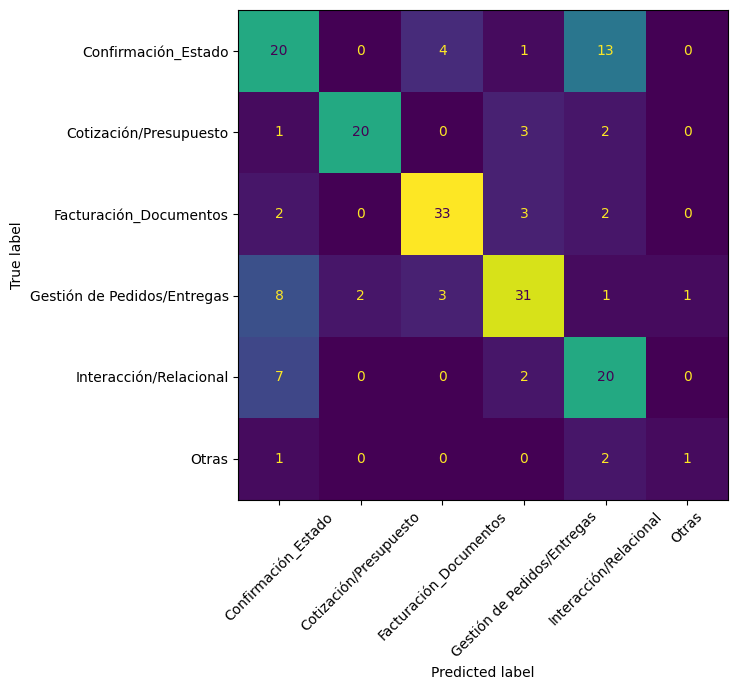

In [5]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred), display_labels=le.classes_).plot(
    ax=ax, xticks_rotation=45, colorbar=False)
plt.tight_layout(); plt.show()

## Validación cruzada estratificada (5 folds)

In [6]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
y_cv = cross_val_predict(pipe, X, y, cv=skf, n_jobs=1,
                         params={"xgb__sample_weight": compute_sample_weight("balanced", y)})
print(classification_report(y, y_cv, target_names=le.classes_, zero_division=0))
print("F1 macro (CV):", round(f1_score(y, y_cv, average="macro"), 3))

                             precision    recall  f1-score   support

        Confirmación_Estado       0.62      0.56      0.59       192
     Cotización/Presupuesto       0.86      0.77      0.81       129
     Facturación_Documentos       0.86      0.84      0.85       198
Gestión de Pedidos/Entregas       0.79      0.78      0.78       228
     Interacción/Relacional       0.56      0.76      0.65       146
                      Otras       0.71      0.25      0.37        20

                   accuracy                           0.73       913
                  macro avg       0.73      0.66      0.68       913
               weighted avg       0.74      0.73      0.73       913

F1 macro (CV): 0.675


## Términos más importantes

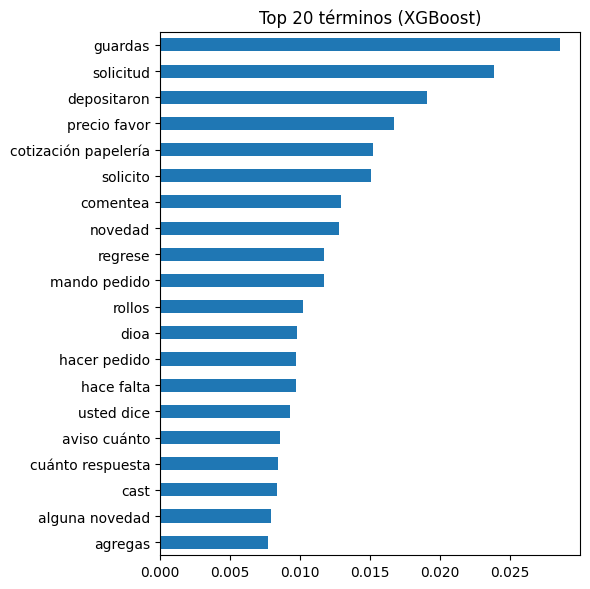

In [7]:
names = X.columns[pipe.named_steps["var"].get_support()]
imp = pd.Series(pipe.named_steps["xgb"].feature_importances_, index=names).nlargest(20)
imp[::-1].plot.barh(figsize=(6, 6), title="Top 20 términos (XGBoost)")
plt.tight_layout(); plt.show()

## Grid Search
Búsqueda de hiperparámetros con validación cruzada estratificada sobre el train set, optimizando F1 macro. El test set solo se usa al final.

In [8]:
from sklearn.model_selection import GridSearchCV
import time

param_grid = {
    "xgb__max_depth":        [3, 6],
    "xgb__learning_rate":    [0.05, 0.1],
    "xgb__n_estimators":     [200, 400],
    "xgb__colsample_bytree": [0.3, 0.5],
    "xgb__min_child_weight": [1, 3],
}

grid = GridSearchCV(
    pipe, param_grid,
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=1, refit=True, verbose=1,
)

t0 = time.time()
grid.fit(X_tr, y_tr, xgb__sample_weight=compute_sample_weight("balanced", y_tr))
print(f"Tiempo: {time.time() - t0:.0f}s")
print("Mejores parámetros:", grid.best_params_)
print("F1 macro (CV, train):", round(grid.best_score_, 3))

Fitting 5 folds for each of 32 candidates, totalling 160 fits


Tiempo: 1995s
Mejores parámetros: {'xgb__colsample_bytree': 0.5, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 6, 'xgb__min_child_weight': 1, 'xgb__n_estimators': 200}
F1 macro (CV, train): 0.65


In [9]:
res = pd.DataFrame(grid.cv_results_)
cols = [c for c in res.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score"]
res[cols].sort_values("mean_test_score", ascending=False).head(10)

,param_xgb__colsample_bytree,param_xgb__learning_rate,param_xgb__max_depth,param_xgb__min_child_weight,param_xgb__n_estimators,mean_test_score,std_test_score
20,0.5,0.05,6,1,200,0.650226,0.048826
8,0.3,0.10,3,1,200,0.643869,0.041318
21,0.5,0.05,6,1,400,0.640708,0.043383
28,0.5,0.10,6,1,200,0.640586,0.042717
17,0.5,0.05,3,1,400,0.638931,0.053389
24,0.5,0.10,3,1,200,0.637514,0.050390
9,0.3,0.10,3,1,400,0.637375,0.045308
12,0.3,0.10,6,1,200,0.636365,0.048410
25,0.5,0.10,3,1,400,0.635657,0.049438
1,0.3,0.05,3,1,400,0.635162,0.049033


In [10]:
best = grid.best_estimator_
y_pred_best = best.predict(X_te)

print(classification_report(y_te, y_pred_best, target_names=le.classes_, zero_division=0))
print("F1 macro test  — base:", round(f1_score(y_te, y_pred, average="macro"), 3),
      "| grid:", round(f1_score(y_te, y_pred_best, average="macro"), 3))

                             precision    recall  f1-score   support

        Confirmación_Estado       0.51      0.55      0.53        38
     Cotización/Presupuesto       0.95      0.73      0.83        26
     Facturación_Documentos       0.89      0.82      0.86        40
Gestión de Pedidos/Entregas       0.82      0.72      0.77        46
     Interacción/Relacional       0.47      0.69      0.56        29
                      Otras       0.50      0.25      0.33         4

                   accuracy                           0.69       183
                  macro avg       0.69      0.63      0.65       183
               weighted avg       0.73      0.69      0.70       183

F1 macro test  — base: 0.635 | grid: 0.645
